# Recomendação de treino por cluster — TCC

Personaliza o **próximo treino** com o perfil do atleta obtido no KMeans:

| Perfil | Ideia de treino |
|--------|-----------------|
| **Volume alto** | Mais longão/ritmo/intervalado; distâncias calibradas no grupo |
| **Volume moderado** | Mais corrida leve; distâncias menores |

Comparamos a recomendação **global** (mesma meta para todos) com a **por cluster**.


In [8]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from dataset.analise import carregar_dataset
from dataset.categorizar.kmeans import treina_kmeans_por_genero
from dataset.categorizar.nomear_clusters import nomear_categorias, tabela_descritiva_clusters
from dataset.constants import COL_ATHLETE, COL_DISTANCE, COL_PACE
from dataset.models.previsao_treino.model import (
    META,
    calibrar_parametros,
    plotar_recomendacao_atleta,
    treina_modelo,
)
from dataset.models.previsao_treino.recomendacao_cluster import (
    META_POR_PERFIL,
    atletas_exemplo_por_perfil,
    calibrar_parametros_por_perfil,
    comparar_recomendacoes,
    exibir_card_recomendacao,
    gerar_recomendacoes_por_cluster,
    resumo_comparacao,
)
from dataset.preprocessamento import formatar_pace, preprocessar


## 1. Dados, clusters e nomes de perfil


In [9]:
df_raw = carregar_dataset(root / "dataset/raw-data-kaggle.csv")
df = preprocessar(df_raw)

resultado_km = treina_kmeans_por_genero(
    df,
    features=[COL_DISTANCE, COL_PACE],
    n_clusters=2,
    plotar=False,
    verbose=False,
)
perfil = nomear_categorias(resultado_km.df_exibir)

print(f"Corridas: {df.height} | Atletas: {perfil.height}")
display(tabela_descritiva_clusters(perfil).select(
    "categoria", "rotulo_cluster", "atletas", "dist_km_med", "pace_med", "freq_semana_med"
))


Corridas: 40534 | Atletas: 114


categoria,rotulo_cluster,atletas,dist_km_med,pace_med,freq_semana_med
str,str,u32,f64,str,f64
"""C0-F""","""Volume alto · Feminino""",18,10.08,"""5:55/km""",1.97
"""C0-M""","""Volume alto · Masculino""",68,10.66,"""5:24/km""",2.08
"""C1-F""","""Volume moderado · Feminino""",12,7.1,"""6:31/km""",1.42
"""C1-M""","""Volume moderado · Masculino""",16,6.96,"""5:52/km""",1.2


## 2. Metas e parâmetros — global vs por perfil

- **Global:** meta fixa 60% leve / 20% longão / 12% ritmo / 8% intervalado.
- **Por perfil:** metas ajustadas + distância/pace calibrados no histórico do cluster.


In [10]:
print("META global:")
for tipo, pct in META.items():
    print(f"  {tipo:12s}: {pct * 100:.0f}%")

print("\nMETA por perfil:")
for chave, meta in META_POR_PERFIL.items():
    print(f"  {chave}:")
    for tipo, pct in meta.items():
        print(f"    {tipo:12s}: {pct * 100:.0f}%")

params_global = calibrar_parametros(df)
params_perfil = calibrar_parametros_por_perfil(df, perfil)

print("\nParâmetros calibrados (distância km | pace_offset):")
print("  [global]")
for tipo, p in params_global.items():
    print(f"    {tipo:12s}: {p['distancia_km']} | {p['pace_offset_min']:+.2f}")

for chave, params in sorted(params_perfil.items()):
    print(f"  [{chave}]")
    for tipo, p in params.items():
        print(f"    {tipo:12s}: {p['distancia_km']} | {p['pace_offset_min']:+.2f}")


META global:
  leve        : 60%
  longao      : 20%
  ritmo       : 12%
  intervalado : 8%

META por perfil:
  volume_alto:
    leve        : 50%
    longao      : 25%
    ritmo       : 15%
    intervalado : 10%
  volume_moderado:
    leve        : 70%
    longao      : 15%
    ritmo       : 10%
    intervalado : 5%

Parâmetros calibrados (distância km | pace_offset):
  [global]
    leve        : (7.6, 10.3) | +0.23
    longao      : (14.0, 18.9) | +0.14
    ritmo       : (7.7, 10.4) | +0.18
    intervalado : (8.1, 11.0) | -0.69
  [volume_alto]
    leve        : (7.9, 10.7) | +0.15
    longao      : (14.3, 19.4) | +0.11
    ritmo       : (8.1, 11.0) | +0.21
    intervalado : (8.5, 11.5) | -0.65
  [volume_moderado]
    leve        : (5.8, 7.9) | +0.11
    longao      : (11.4, 15.4) | +0.21
    ritmo       : (5.6, 7.6) | +0.33
    intervalado : (5.7, 7.7) | -0.72


## 3. Gerar recomendações


In [11]:
baseline = treina_modelo(df, plotar=False, verbose=False)
rec_global = baseline.recomendacoes
rec_cluster = gerar_recomendacoes_por_cluster(df, perfil)

print(f"Recomendações globais:     {rec_global.height}")
print(f"Recomendações por cluster: {rec_cluster.height}")

display(
    rec_cluster.select(
        COL_ATHLETE, "rotulo_cluster", "tipo", "distancia_km", "pace_alvo_min_km", "tempo_estimado_min", "erro_distribuicao"
    ).head(10)
)


Recomendações globais:     104
Recomendações por cluster: 104


athlete,rotulo_cluster,tipo,distancia_km,pace_alvo_min_km,tempo_estimado_min,erro_distribuicao
i64,str,str,f64,f64,f64,f64
1776170,"""Volume alto · Masculino""","""longao""",16.9,5.99,100.9,0.833
2013538,"""Volume alto · Masculino""","""ritmo""",9.6,5.17,49.4,0.5
2081128,"""Volume alto · Masculino""","""leve""",9.3,5.23,48.6,1.086
2138770,"""Volume alto · Masculino""","""leve""",9.3,4.87,45.3,1.2
2683270,"""Volume alto · Masculino""","""longao""",16.9,5.75,96.9,1.0
2913078,"""Volume alto · Feminino""","""longao""",16.9,8.3,139.9,1.0
3460571,"""Volume alto · Masculino""","""intervalado""",10.0,6.14,61.4,0.367
3539760,"""Volume alto · Masculino""","""longao""",16.9,6.11,103.0,0.7
3573750,"""Volume alto · Masculino""","""intervalado""",10.0,5.57,55.7,0.422


## 4. Comparação — genérico vs personalizado


Resumo da comparação:
  n_atletas: 104
  pct_tipo_mudou: 16.3
  delta_dist_medio_km: 0.45
  delta_pace_medio: -0.111
  erro_global_medio: 0.763
  erro_cluster_medio: 0.731

Amostra:


athlete,rotulo_cluster,tipo_global,tipo_cluster,dist_global,dist_cluster,delta_dist_km,tipo_mudou
i64,str,str,str,f64,f64,f64,bool
2913078,"""Volume alto · Feminino""","""longao""","""longao""",16.4,16.9,0.5,false
5035018,"""Volume alto · Feminino""","""leve""","""leve""",8.9,9.3,0.4,false
11088529,"""Volume alto · Feminino""","""leve""","""leve""",8.9,9.3,0.4,false
11348733,"""Volume alto · Feminino""","""leve""","""leve""",8.9,9.3,0.4,false
12740383,"""Volume alto · Feminino""","""leve""","""leve""",8.9,9.3,0.4,false
…,…,…,…,…,…,…,…
20181492,"""Volume alto · Feminino""","""leve""","""leve""",8.9,9.3,0.4,false
22835898,"""Volume alto · Feminino""","""leve""","""longao""",8.9,16.9,8.0,true
22843389,"""Volume alto · Feminino""","""leve""","""intervalado""",8.9,10.0,1.1,true


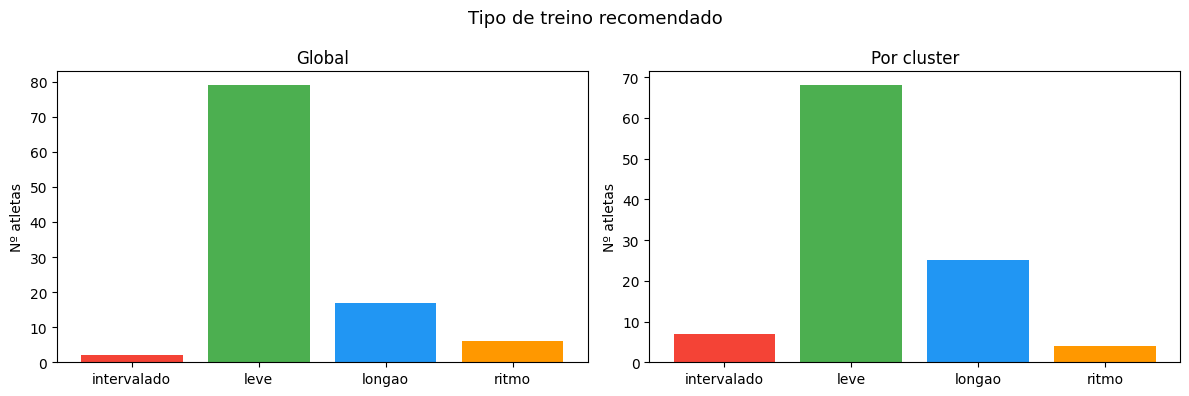

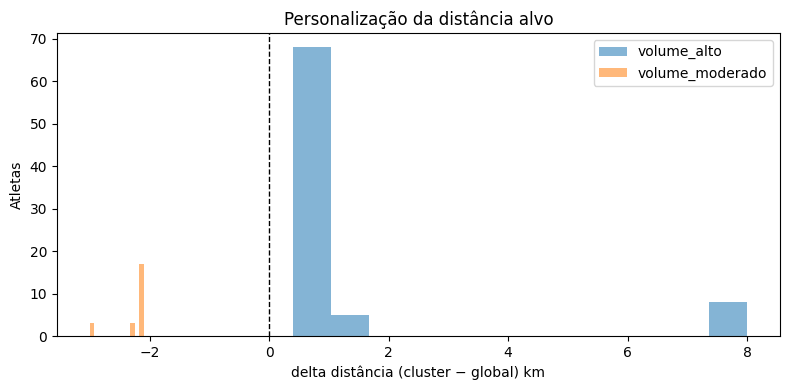

In [12]:
comparacao = comparar_recomendacoes(rec_global, rec_cluster)
resumo = resumo_comparacao(comparacao)

print("Resumo da comparação:")
for k, v in resumo.items():
    print(f"  {k}: {v}")

print("\nAmostra:")
display(
    comparacao.select(
        COL_ATHLETE,
        "rotulo_cluster",
        "tipo_global",
        "tipo_cluster",
        "dist_global",
        "dist_cluster",
        "delta_dist_km",
        "tipo_mudou",
    ).head(15)
)

# distribuição de tipos recomendados
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (titulo, rec) in zip(
    axes,
    [("Global", rec_global), ("Por cluster", rec_cluster)],
):
    cont = rec.group_by("tipo").agg(pl.len().alias("qtd")).sort("tipo")
    cores = {"leve": "#4CAF50", "longao": "#2196F3", "ritmo": "#FF9800", "intervalado": "#F44336"}
    ax.bar(
        cont["tipo"].to_list(),
        cont["qtd"].to_list(),
        color=[cores.get(t, "gray") for t in cont["tipo"].to_list()],
    )
    ax.set_title(titulo)
    ax.set_ylabel("Nº atletas")
fig.suptitle("Tipo de treino recomendado", fontsize=13)
plt.tight_layout()
plt.show()

# delta de distância por perfil
fig, ax = plt.subplots(figsize=(8, 4))
for perfil_chave in sorted(comparacao["perfil_cluster"].unique().to_list()):
    sub = comparacao.filter(pl.col("perfil_cluster") == perfil_chave)
    ax.hist(sub["delta_dist_km"].to_numpy(), bins=12, alpha=0.55, label=perfil_chave)
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_xlabel("delta distância (cluster − global) km")
ax.set_ylabel("Atletas")
ax.set_title("Personalização da distância alvo")
ax.legend()
plt.tight_layout()
plt.show()


## 5. Cards — um atleta por categoria

Vitrine para o TCC: card de recomendação personalizada por perfil.

Atletas-exemplo: [12740383, 18042525, 37124981, 23729907]
Atleta 12740383  ·  Volume alto · Feminino
Janela: últimas 6 semanas
------------------------------------------------------------
Distribuição atual vs meta do perfil:
  • intervalado :  64.3%  (meta: 10%)
  • longao      :  14.3%  (meta: 25%)
  • leve        :  14.3%  (meta: 50%)
  • ritmo       :   7.1%  (meta: 15%)
------------------------------------------------------------
Próximo treino: LEVE
  Corrida leve / regenerativa
  Distância:      9.3 km
  Pace alvo:      5:37/km
  Tempo estimado: 52 min
  Erro vs meta:   1.086


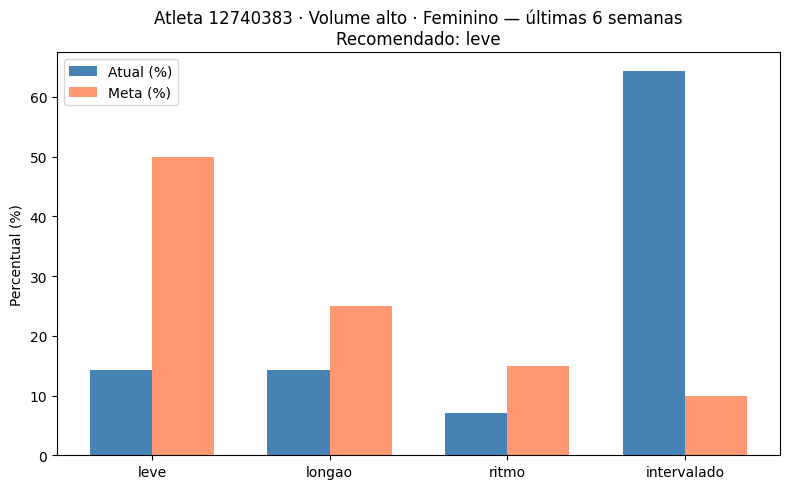

Atleta 18042525  ·  Volume alto · Masculino
Janela: últimas 6 semanas
------------------------------------------------------------
Distribuição atual vs meta do perfil:
  • ritmo       :  25.0%  (meta: 15%)
  • leve        :  50.0%  (meta: 50%)
  • intervalado :  25.0%  (meta: 10%)
------------------------------------------------------------
Próximo treino: LONGAO
  Longão em ritmo confortável
  Distância:      16.9 km
  Pace alvo:      5:35/km
  Tempo estimado: 94 min
  Erro vs meta:   0.5


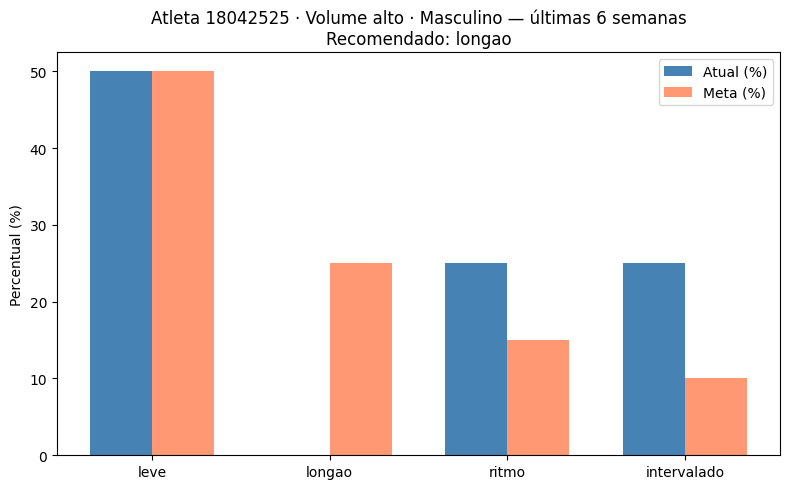

Atleta 37124981  ·  Volume moderado · Feminino
Janela: últimas 6 semanas
------------------------------------------------------------
Distribuição atual vs meta do perfil:
  • longao      :  50.0%  (meta: 15%)
  • leve        :  50.0%  (meta: 70%)
------------------------------------------------------------
Próximo treino: LEVE
  Corrida leve / regenerativa
  Distância:      6.8 km
  Pace alvo:      7:22/km
  Tempo estimado: 50 min
  Erro vs meta:   0.7


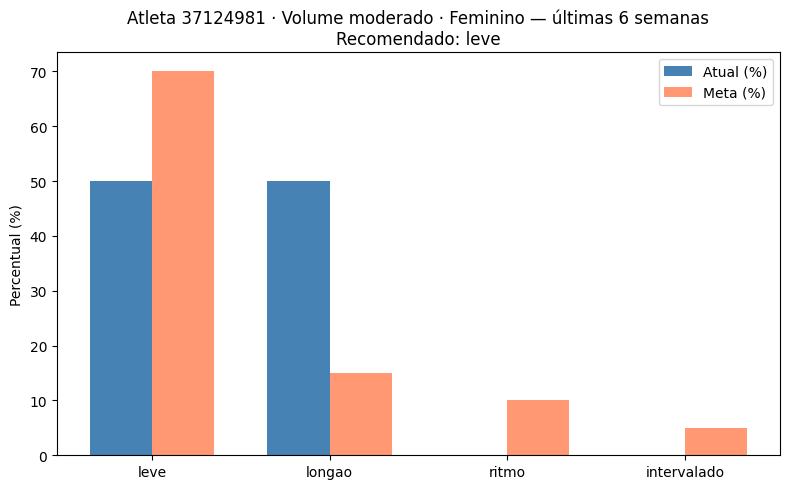

Atleta 23729907  ·  Volume moderado · Masculino
Janela: últimas 6 semanas
------------------------------------------------------------
Distribuição atual vs meta do perfil:
  • longao      :  22.2%  (meta: 15%)
  • ritmo       :  11.1%  (meta: 10%)
  • intervalado :  22.2%  (meta: 5%)
  • leve        :  44.4%  (meta: 70%)
------------------------------------------------------------
Próximo treino: LEVE
  Corrida leve / regenerativa
  Distância:      6.8 km
  Pace alvo:      6:27/km
  Tempo estimado: 44 min
  Erro vs meta:   0.511


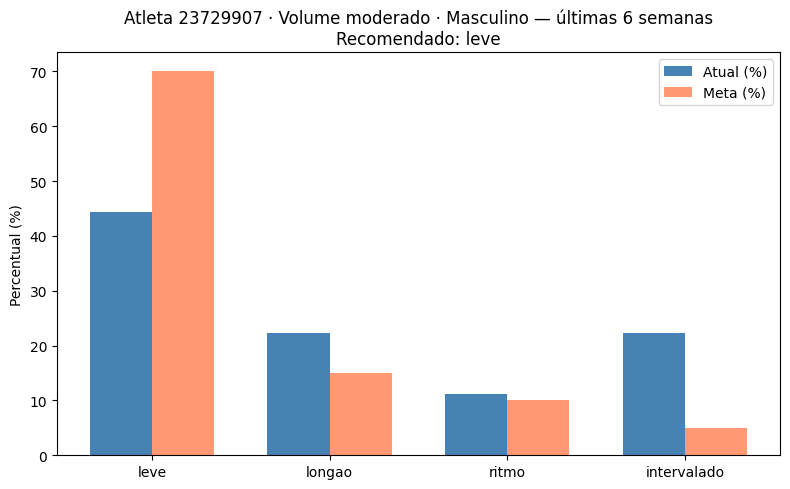

In [13]:
exemplos = atletas_exemplo_por_perfil(perfil, seed=42)

print("Atletas-exemplo:", exemplos)
for aid in exemplos:
    exibir_card_recomendacao(df, rec_cluster, aid)
    chave = rec_cluster.filter(pl.col(COL_ATHLETE) == aid)["perfil_cluster"][0]
    plotar_recomendacao_atleta(df, rec_cluster, aid, meta=META_POR_PERFIL[chave])


## 6. Inspeção individual

Altere `ATLETA_ID` para explorar outro corredor.


Atleta 12740383 — Volume alto · Feminino
  Global:  LEVE | 8.9 km | pace 5:42/km
  Cluster: LEVE | 9.3 km | pace 5:37/km
  Tipo mudou: False | Δ dist: +0.40 km
Atleta 12740383  ·  Volume alto · Feminino
Janela: últimas 6 semanas
------------------------------------------------------------
Distribuição atual vs meta do perfil:
  • leve        :  14.3%  (meta: 50%)
  • longao      :  14.3%  (meta: 25%)
  • intervalado :  64.3%  (meta: 10%)
  • ritmo       :   7.1%  (meta: 15%)
------------------------------------------------------------
Próximo treino: LEVE
  Corrida leve / regenerativa
  Distância:      9.3 km
  Pace alvo:      5:37/km
  Tempo estimado: 52 min
  Erro vs meta:   1.086


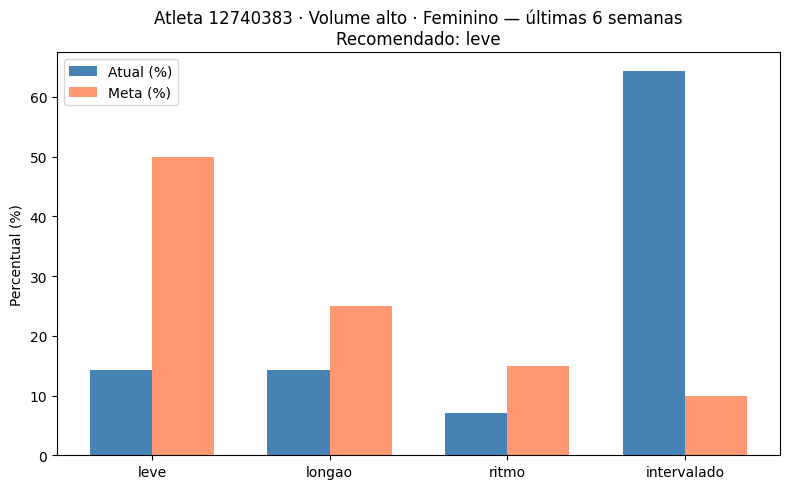

In [14]:
ATLETA_ID = exemplos[0]

linha_cmp = comparacao.filter(pl.col(COL_ATHLETE) == ATLETA_ID)
if linha_cmp.height:
    r = linha_cmp.row(0, named=True)
    print(f"Atleta {ATLETA_ID} — {r['rotulo_cluster']}")
    print(f"  Global:  {r['tipo_global'].upper()} | {r['dist_global']:.1f} km | pace {formatar_pace(r['pace_global'])}")
    print(f"  Cluster: {r['tipo_cluster'].upper()} | {r['dist_cluster']:.1f} km | pace {formatar_pace(r['pace_cluster'])}")
    print(f"  Tipo mudou: {r['tipo_mudou']} | Δ dist: {r['delta_dist_km']:+.2f} km")

exibir_card_recomendacao(df, rec_cluster, ATLETA_ID)
chave = rec_cluster.filter(pl.col(COL_ATHLETE) == ATLETA_ID)["perfil_cluster"][0]
plotar_recomendacao_atleta(df, rec_cluster, ATLETA_ID, meta=META_POR_PERFIL[chave])


## 7. Resumo

- Clusters **Volume alto / Volume moderado** (por gênero) ajustam **meta semanal** e **distância/pace alvo**.
- A recomendação por cluster é a camada pronta para o endpoint `/analyze` (perfil + cluster + próximo treino).
- Use a seção de comparação para justificar, na monografia, o ganho da personalização vs. regras globais.
